# ANN Backpropagation: NumPy dan TensorFlow/Keras

Eksperimen prediksi kurs USD/IDR dengan arsitektur MLP 4–h–1. Notebook ini dimulai dari implementasi rumus menggunakan NumPy, lalu membandingkannya dengan TensorFlow/Keras.

**Alur:** validasi hitungan manual → training 18 model NumPy → evaluasi dan diagnostik underfitting → training 18 model Keras → perbandingan → forecast 2024–2025.

## 1. Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

np.set_printoptions(precision=8, suppress=True)
pd.set_option("display.max_columns", None)

SEED = 42
LEARNING_RATE = 0.1
EPOCHS = 1000
HIDDEN_LIST = [5, 10, 15, 20, 25, 30]

INPUT_COLUMNS = ["x1", "x2", "x3", "x4"]
TARGET_COLUMN = "t"
SET_COLUMN = "set"

MIN_DATA = 13572.5
MAX_DATA = 16575.0

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
Pandas: 2.2.3


## 2. Data dan konfigurasi

File split sudah berisi data yang dinormalisasi dan penanda `train`/`test`. Data tidak dinormalisasi ulang dan tidak diacak kembali. Pre-process data dilakukan di notebook yang berbeda.

- `x1`–`x4`: empat nilai historis sebagai input.
- `t`: target ternormalisasi.
- `t_rp`: target dalam Rupiah.
- `t_is_filled`: penanda nilai hasil pengisian.
- `t_is_thin`: penanda hari libur atau rentang harian tipis.

Training mengikuti seluruh baris pada bagian train. Evaluasi utama hanya memakai `t_is_filled = 0`; evaluasi ketat juga mensyaratkan `t_is_thin = 0`.

In [2]:
SPLIT_STEMS = {
    "90:10": "split_90_10",
    "80:20": "split_80_20",
    "70:30": "split_70_30",
}

def find_csv(stem, required=True):
    matches = sorted(Path(".").glob(f"{stem}*.csv"))
    if not matches:
        return None
    exact = Path(f"{stem}.csv")
    return exact if exact.exists() else matches[0]

required_stems = list(SPLIT_STEMS.values())
missing = [stem for stem in required_stems if find_csv(stem) is None]

if missing:
    try:
        from google.colab import files
        print("Upload file CSV yang belum tersedia:", missing)
        files.upload()
    except Exception:
        print("Letakkan ketiga file split di folder yang sama dengan notebook.")

split_dfs = {}
for scenario, stem in SPLIT_STEMS.items():
    file_path = find_csv(stem)
    if file_path is None:
        raise FileNotFoundError(f"File {stem}.csv belum ditemukan.")
    split_dfs[scenario] = pd.read_csv(file_path)

forecast_path = find_csv("forecast_inputs_norm", required=False)
forecast_df = pd.read_csv(forecast_path) if forecast_path is not None else None

for scenario, df in split_dfs.items():
    required = INPUT_COLUMNS + [TARGET_COLUMN, "t_rp", SET_COLUMN, "t_is_filled", "t_is_thin"]
    missing_cols = [c for c in required if c not in df.columns]
    if missing_cols:
        raise ValueError(f"{scenario}: kolom tidak ditemukan: {missing_cols}")

    set_values = df[SET_COLUMN].astype(str).str.strip().str.lower()
    n_train = int((set_values == "train").sum())
    n_test = int((set_values == "test").sum())
    print(
        f"{scenario}: total={len(df)}, train={n_train}, test={n_test}, "
        f"test valid={(df.loc[set_values == 'test', 't_is_filled'] == 0).sum()}"
    )

print("File forecast:", forecast_path if forecast_path is not None else "tidak tersedia")

90:10: total=365, train=329, test=36, test valid=26
80:20: total=365, train=292, test=73, test valid=53
70:30: total=365, train=256, test=109, test valid=78
File forecast: forecast_inputs_norm.csv


### 3. Rumus dan Fungsi Dasar

Model yang digunakan adalah **Multilayer Perceptron (MLP)** dengan satu hidden layer. Fungsi aktivasi yang digunakan pada hidden layer dan output layer adalah sigmoid biner.

**1. Fungsi Aktivasi Sigmoid**

Fungsi sigmoid digunakan untuk mengubah nilai masukan ke dalam rentang 0 sampai 1.

$$
f(u)=\frac{1}{1+e^{-u}}
$$

**2. Forward Propagation**

Proses forward propagation dilakukan untuk memperoleh nilai prediksi melalui dua tahapan.

Kombinasi linear pada hidden layer:

$$
U_1=XV+b_1
$$

Aktivasi hidden layer:

$$
Z=f(U_1)
$$

Kombinasi linear pada output layer:

$$
U_2=ZW+b_2
$$

Hasil prediksi:

$$
\hat{Y}=f(U_2)
$$

**3. Mean Squared Error (MSE)**

MSE digunakan untuk mengukur rata-rata kuadrat selisih antara nilai aktual dan nilai prediksi.

$$
MSE=\frac{1}{N}\sum_{i=1}^{N}(Y_i-\hat{Y}_i)^2
$$

Untuk perhitungan gradien pada backpropagation, fungsi objektif dituliskan sebagai:

$$
E=\frac{1}{2N}\sum_{i=1}^{N}(Y_i-\hat{Y}_i)^2
$$

**4. Denormalisasi**

Denormalisasi dilakukan untuk mengembalikan hasil prediksi dari skala normalisasi ke nilai kurs dalam Rupiah.

Rumus normalisasi:

$$
x' = 0,8\left(\frac{x-b}{a-b}\right)+0,1
$$

Rumus denormalisasi:

$$
x=\frac{(x'-0,1)(a-b)}{0,8}+b
$$

Dengan keterangan:

- \(x'\) = nilai setelah normalisasi.
- \(x\) = nilai sebelum normalisasi.
- \(a\) = nilai maksimum data.
- \(b\) = nilai minimum data.

In [3]:
def sigmoid(u):
    u = np.clip(u, -500, 500)
    return 1.0 / (1.0 + np.exp(-u))


def forward_propagation(X, params):
    V, b1 = params["V"], params["b1"]
    W, b2 = params["W"], params["b2"]

    U1 = X @ V + b1
    Z = sigmoid(U1)
    U2 = Z @ W + b2
    y_hat = sigmoid(U2)

    return U1, Z, U2, y_hat


def mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))


def denormalize(x_norm):
    return (x_norm - 0.1) * (MAX_DATA - MIN_DATA) / 0.8 + MIN_DATA


def initialize_parameters(n_hidden, seed=SEED):
    rng = np.random.default_rng(seed)

    limit_V = np.sqrt(6.0 / (4 + n_hidden))
    limit_W = np.sqrt(6.0 / (n_hidden + 1))

    return {
        "V": rng.uniform(-limit_V, limit_V, size=(4, n_hidden)),
        "b1": np.zeros((1, n_hidden)),
        "W": rng.uniform(-limit_W, limit_W, size=(n_hidden, 1)),
        "b2": np.zeros((1, 1)),
    }

## 4. Validasi dengan hitungan manual

Bagian ini menggunakan data, bobot, bias, dan learning rate dari perumusan manual. Arsitektur 4–2–1 dipakai untuk memeriksa satu iterasi forward pass, backpropagation, dan pembaruan parameter.

In [4]:
X_manual = np.array([[0.244546, 0.306495, 0.280516, 0.303164]])
y_manual = np.array([[0.541632]])

params_manual = {
    "V": np.array([
        [ 0.20, -0.10],
        [-0.30,  0.40],
        [ 0.15,  0.25],
        [ 0.35, -0.20],
    ]),
    "b1": np.array([[0.10, 0.05]]),
    "W": np.array([[0.40], [-0.30]]),
    "b2": np.array([[0.20]]),
}

alpha_manual = 0.1
U1_m, Z_m, U2_m, yhat_m = forward_propagation(X_manual, params_manual)

delta2_m = (yhat_m - y_manual) * yhat_m * (1 - yhat_m)
grad_W_m = Z_m.T @ delta2_m
grad_b2_m = np.mean(delta2_m, axis=0, keepdims=True)

delta1_m = (delta2_m @ params_manual["W"].T) * Z_m * (1 - Z_m)
grad_V_m = X_manual.T @ delta1_m
grad_b1_m = np.mean(delta1_m, axis=0, keepdims=True)

updated_manual = {
    "V": params_manual["V"] - alpha_manual * grad_V_m,
    "b1": params_manual["b1"] - alpha_manual * grad_b1_m,
    "W": params_manual["W"] - alpha_manual * grad_W_m,
    "b2": params_manual["b2"] - alpha_manual * grad_b2_m,
}

print("U1 =", U1_m)
print("Z =", Z_m)
print("Prediksi =", yhat_m)
print("MSE =", mse(y_manual, yhat_m))
print("Delta output =", delta2_m)
print("Delta hidden =", delta1_m)
print("W baru =\n", updated_manual["W"])
print("b2 baru =", updated_manual["b2"])
print("b1 baru =", updated_manual["b1"])

assert np.allclose(U1_m, [[0.2051455, 0.1576396]], atol=1e-7)
assert np.allclose(Z_m, [[0.5511072645, 0.5393284902]], atol=1e-7)
assert np.allclose(yhat_m, [[0.5643030261]], atol=1e-7)
assert abs(mse(y_manual, yhat_m) - 0.0005139742) < 1e-8
assert np.allclose(updated_manual["W"].ravel(), [0.3996928, -0.3003006], atol=2e-6)
assert np.allclose(updated_manual["b2"], [[0.1994426]], atol=2e-6)
assert np.allclose(updated_manual["b1"], [[0.0999448, 0.0500415]], atol=2e-6)

print("Validasi berhasil.")

U1 = [[0.2051455 0.1576396]]
Z = [[0.55110726 0.53932849]]
Prediksi = [[0.56430302]]
MSE = 0.0005139749668559653
Delta output = [[0.00557401]]
Delta hidden = [[ 0.00055158 -0.00041546]]
W baru =
 [[ 0.39969281]
 [-0.30030062]]
b2 baru = [[0.1994426]]
b1 baru = [[0.09994484 0.05004155]]
Validasi berhasil.


## 5. Backpropagation dan training NumPy

Bobot awal untuk eksperimen penuh tidak ditetapkan dalam hitungan manual, sehingga digunakan inisialisasi Xavier/Glorot dan bias nol. Seed dibuat tetap agar hasil dapat diulang. Setiap epoch menggunakan seluruh data training dalam satu batch.

In [5]:
def backpropagation_gradients(X, y, params):
    n = X.shape[0]
    _, Z, _, y_hat = forward_propagation(X, params)

    delta2 = (y_hat - y) * y_hat * (1 - y_hat)
    grad_W = (Z.T @ delta2) / n
    grad_b2 = np.mean(delta2, axis=0, keepdims=True)

    delta1 = (delta2 @ params["W"].T) * Z * (1 - Z)
    grad_V = (X.T @ delta1) / n
    grad_b1 = np.mean(delta1, axis=0, keepdims=True)

    return {
        "V": grad_V,
        "b1": grad_b1,
        "W": grad_W,
        "b2": grad_b2,
    }


def train_numpy(X, y, n_hidden, initial_params, epochs=EPOCHS, learning_rate=LEARNING_RATE):
    params = {k: v.copy() for k, v in initial_params.items()}
    history = []

    for epoch in range(1, epochs + 1):
        gradients = backpropagation_gradients(X, y, params)

        for key in params:
            params[key] -= learning_rate * gradients[key]

        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            _, _, _, pred = forward_propagation(X, params)
            history.append({
                "epoch": epoch,
                "mse_training": mse(y, pred),
            })

    return params, pd.DataFrame(history)


def get_xy(df, subset):
    set_values = df[SET_COLUMN].astype(str).str.strip().str.lower()
    part = df.loc[set_values == subset].copy()
    X = part[INPUT_COLUMNS].to_numpy(dtype=np.float64)
    y = part[[TARGET_COLUMN]].to_numpy(dtype=np.float64)
    return part, X, y


def evaluate_predictions(part, y_true, y_pred):
    valid = part["t_is_filled"].to_numpy() == 0
    strict = valid & (part["t_is_thin"].to_numpy() == 0)

    actual_rp = part["t_rp"].to_numpy(dtype=float)
    pred_rp = denormalize(y_pred.reshape(-1))

    result = {
        "n_valid": int(valid.sum()),
        "mse_norm": mse(y_true[valid].reshape(-1), y_pred[valid].reshape(-1)),
        "rmse_rp": float(np.sqrt(np.mean((actual_rp[valid] - pred_rp[valid]) ** 2))),
        "n_strict": int(strict.sum()),
        "mse_strict_norm": mse(y_true[strict].reshape(-1), y_pred[strict].reshape(-1)),
        "rmse_strict_rp": float(np.sqrt(np.mean((actual_rp[strict] - pred_rp[strict]) ** 2))),
    }
    return result

## 6. Training 18 model NumPy

Tiga skenario split dikombinasikan dengan enam pilihan hidden neuron. Evaluasi utama menggunakan target asli (`t_is_filled = 0`), sedangkan versi ketat juga mengeluarkan data `t_is_thin = 1`.

In [6]:
numpy_models = {}
numpy_histories = {}
numpy_predictions = {}
numpy_rows = []

for scenario, df in split_dfs.items():
    train_part, X_train, y_train = get_xy(df, "train")
    test_part, X_test, y_test = get_xy(df, "test")

    for n_hidden in HIDDEN_LIST:
        seed_model = SEED + n_hidden
        initial = initialize_parameters(n_hidden, seed=seed_model)

        params, history = train_numpy(
            X_train, y_train, n_hidden, initial,
            epochs=EPOCHS, learning_rate=LEARNING_RATE
        )

        pred_train = forward_propagation(X_train, params)[-1]
        pred_test = forward_propagation(X_test, params)[-1]

        train_metrics = evaluate_predictions(train_part, y_train, pred_train)
        test_metrics = evaluate_predictions(test_part, y_test, pred_test)

        rw_valid = test_part["t_is_filled"].to_numpy() == 0
        rw_strict = rw_valid & (test_part["t_is_thin"].to_numpy() == 0)
        rw_pred_rp = denormalize(X_test[:, 3])
        actual_rp = test_part["t_rp"].to_numpy(dtype=float)

        numpy_models[(scenario, n_hidden)] = params
        numpy_histories[(scenario, n_hidden)] = history
        numpy_predictions[(scenario, n_hidden)] = {
            "train": pred_train,
            "test": pred_test,
        }

        numpy_rows.append({
            "split": scenario,
            "hidden": n_hidden,
            "n_train": len(train_part),
            "n_test": len(test_part),
            "mse_train_norm": train_metrics["mse_norm"],
            "mse_test_norm": test_metrics["mse_norm"],
            "rmse_test_rp": test_metrics["rmse_rp"],
            "mse_test_strict_norm": test_metrics["mse_strict_norm"],
            "rmse_test_strict_rp": test_metrics["rmse_strict_rp"],
            "rmse_random_walk_rp": float(np.sqrt(np.mean(
                (actual_rp[rw_valid] - rw_pred_rp[rw_valid]) ** 2
            ))),
        })

numpy_results = pd.DataFrame(numpy_rows)
display(numpy_results.round(6))

,split,hidden,n_train,n_test,mse_train_norm,mse_test_norm,rmse_test_rp,mse_test_strict_norm,rmse_test_strict_rp,rmse_random_walk_rp
0,90:10,5,329,36,0.007572,0.014059,445.002923,0.014059,445.002923,611.743741
1,90:10,10,329,36,0.007431,0.012041,411.828170,0.012041,411.828170,611.743741
2,90:10,15,329,36,0.006841,0.011473,402.008829,0.011473,402.008829,611.743741
3,90:10,20,329,36,0.007396,0.012606,421.392163,0.012606,421.392163,611.743741
4,90:10,25,329,36,0.006401,0.010331,381.479445,0.010331,381.479445,611.743741
5,90:10,30,329,36,0.006444,0.012431,418.459894,0.012431,418.459894,611.743741
6,80:20,5,292,73,0.007730,0.011846,408.488216,0.012165,413.944360,476.452433
7,80:20,10,292,73,0.007689,0.010139,377.915490,0.010406,382.847678,476.452433
8,80:20,15,292,73,0.007124,0.009291,361.757024,0.009552,366.812017,476.452433
9,80:20,20,292,73,0.007628,0.010575,385.960641,0.010858,391.089931,476.452433


## 7. Grafik konvergensi dan prediksi NumPy

Grafik pertama memperlihatkan perubahan MSE training untuk enam arsitektur pada setiap skenario. Grafik kedua membandingkan prediksi model dengan nilai aktual pada data testing; arsitektur dipilih berdasarkan MSE testing pada baris valid.

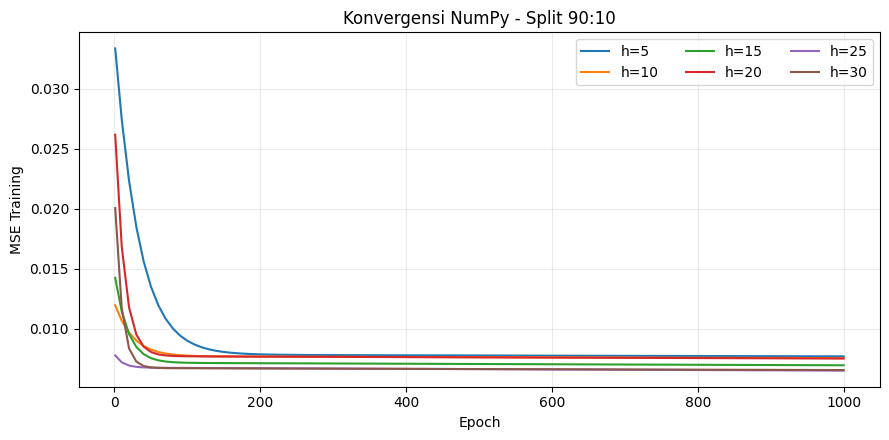

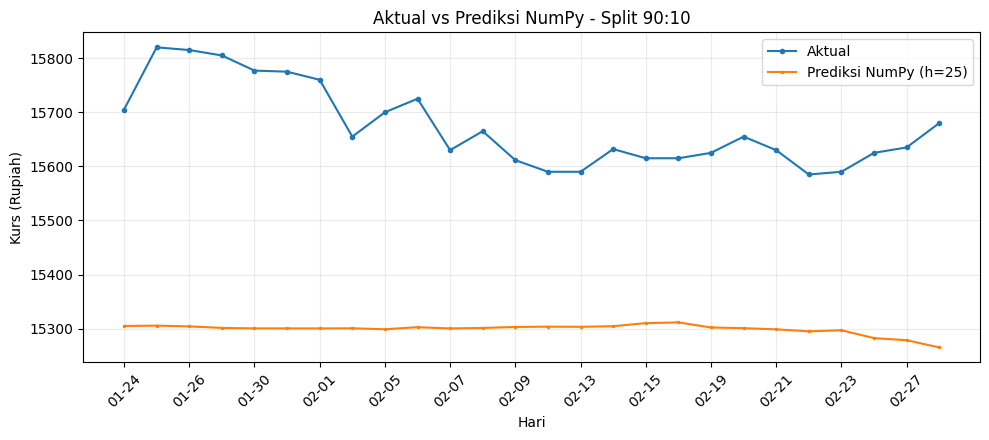

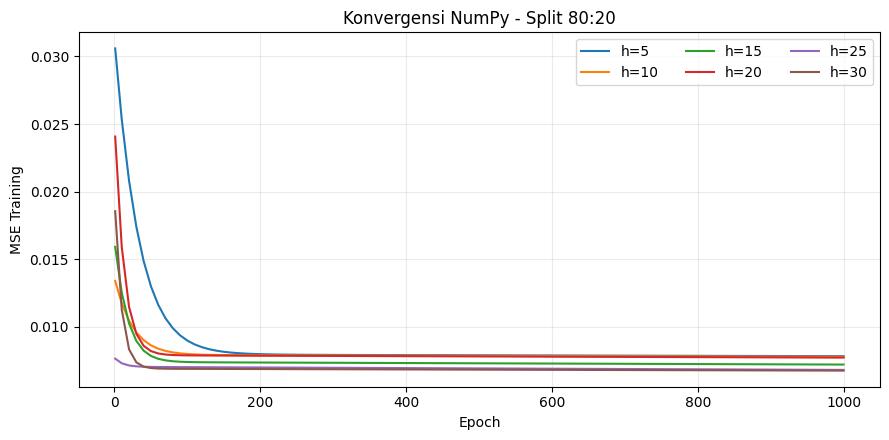

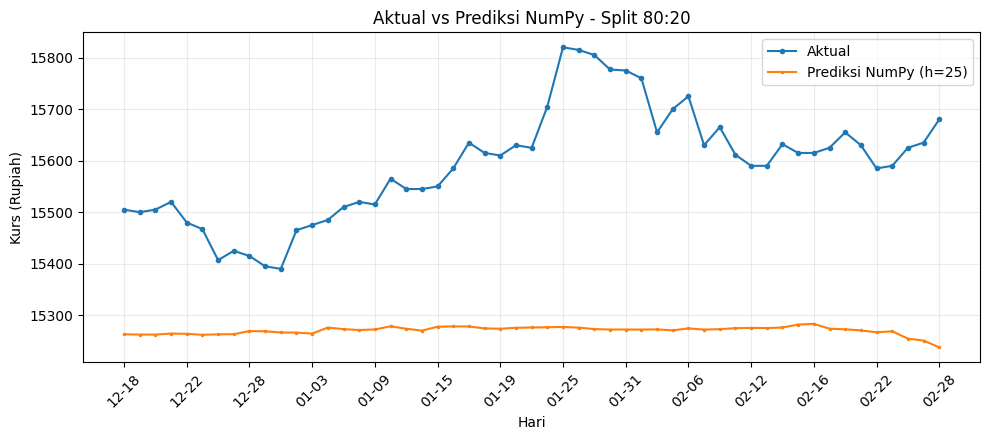

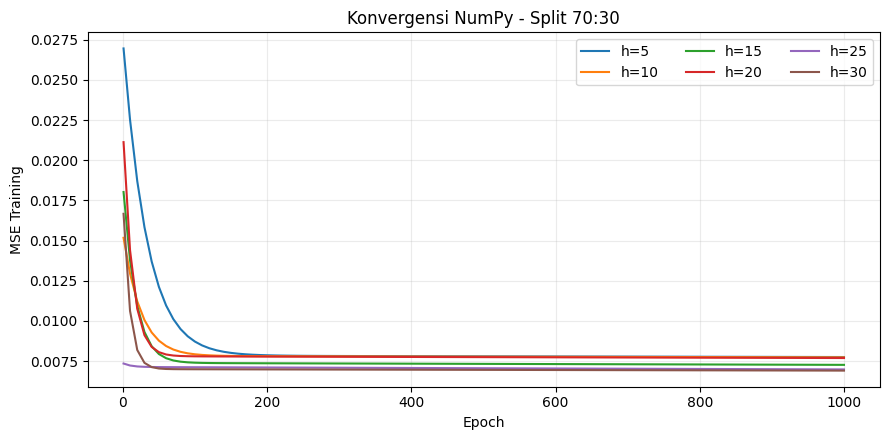

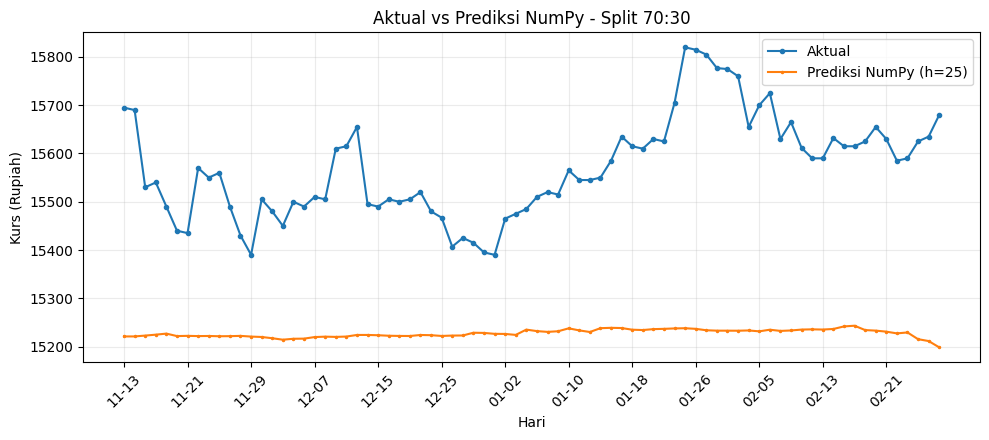

Hidden neuron terbaik per split: {'90:10': 25, '80:20': 25, '70:30': 25}


In [7]:
best_numpy = {}
for scenario in split_dfs:
    scenario_results = numpy_results[numpy_results["split"] == scenario]
    best_hidden = int(scenario_results.sort_values("mse_test_norm").iloc[0]["hidden"])
    best_numpy[scenario] = best_hidden

    plt.figure(figsize=(9, 4.5))
    for n_hidden in HIDDEN_LIST:
        hist = numpy_histories[(scenario, n_hidden)]
        plt.plot(hist["epoch"], hist["mse_training"], label=f"h={n_hidden}")
    plt.title(f"Konvergensi NumPy - Split {scenario}")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Training")
    plt.legend(ncol=3)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    test_part, X_test, y_test = get_xy(split_dfs[scenario], "test")
    pred = numpy_predictions[(scenario, best_hidden)]["test"].reshape(-1)
    valid = test_part["t_is_filled"].to_numpy() == 0

    plt.figure(figsize=(10, 4.5))
    plt.plot(
        test_part.loc[valid, "day"].astype(str),
        test_part.loc[valid, "t_rp"].to_numpy(),
        marker="o", markersize=3, label="Aktual"
    )
    plt.plot(
        test_part.loc[valid, "day"].astype(str),
        denormalize(pred[valid]),
        marker=".", markersize=3, label=f"Prediksi NumPy (h={best_hidden})"
    )
    plt.title(f"Aktual vs Prediksi NumPy - Split {scenario}")
    plt.xlabel("Hari")
    plt.ylabel("Kurs (Rupiah)")
    tick_positions = np.arange(0, int(valid.sum()), max(1, int(valid.sum()) // 12))
    day_labels = test_part.loc[valid, "day"].astype(str).to_numpy()
    plt.xticks(tick_positions, day_labels[tick_positions], rotation=45)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

print("Hidden neuron terbaik per split:", best_numpy)

## 8. Diagnostik underfitting

Indikasi underfitting dilihat dari dua hal: MSE training masih dekat dengan baseline prediksi rata-rata, dan variasi prediksi jauh lebih kecil daripada variasi target aktual. Penilaian ini dilihat bersama grafik, bukan dari selisih MSE training-testing saja.

In [8]:
underfit_rows = []

for scenario, best_hidden in best_numpy.items():
    train_part, X_train, y_train = get_xy(split_dfs[scenario], "train")
    test_part, X_test, y_test = get_xy(split_dfs[scenario], "test")

    pred_train = numpy_predictions[(scenario, best_hidden)]["train"].reshape(-1)
    pred_test = numpy_predictions[(scenario, best_hidden)]["test"].reshape(-1)

    train_valid = train_part["t_is_filled"].to_numpy() == 0
    test_valid = test_part["t_is_filled"].to_numpy() == 0

    y_train_valid = y_train.reshape(-1)[train_valid]
    pred_train_valid = pred_train[train_valid]
    y_test_valid = y_test.reshape(-1)[test_valid]
    pred_test_valid = pred_test[test_valid]

    baseline_train_mse = float(np.mean(
        (y_train_valid - np.mean(y_train_valid)) ** 2
    ))
    train_mse = mse(y_train_valid, pred_train_valid)
    test_mse = mse(y_test_valid, pred_test_valid)

    pred_sd_ratio = float(
        np.std(pred_test_valid) / np.std(y_test_valid)
    )
    train_improvement = float(
        1 - train_mse / baseline_train_mse
    )

    is_underfit = (train_mse >= 0.8 * baseline_train_mse) and (pred_sd_ratio < 0.5)

    underfit_rows.append({
        "split": scenario,
        "hidden_terpilih": best_hidden,
        "mse_train": train_mse,
        "baseline_mse_train": baseline_train_mse,
        "perbaikan_vs_baseline": train_improvement,
        "mse_test": test_mse,
        "std_prediksi/std_aktual": pred_sd_ratio,
        "indikasi": "Underfitting" if is_underfit else "Belum kuat",
    })

underfit_df = pd.DataFrame(underfit_rows)
display(underfit_df.round(5))

,split,hidden_terpilih,mse_train,baseline_mse_train,perbaikan_vs_baseline,mse_test,std_prediksi/std_aktual,indikasi
0,90:10,25,0.00640,0.00717,0.10735,0.01033,0.12853,Underfitting
1,80:20,25,0.00674,0.00738,0.08778,0.00816,0.07194,Underfitting
2,70:30,25,0.00689,0.00736,0.06363,0.00909,0.07659,Underfitting


## 9. ANN menggunakan TensorFlow/Keras

Keras memakai arsitektur, aktivasi, bobot awal, bias awal, learning rate, epoch, dan batch yang sama dengan NumPy. Optimizer `SGD` dengan momentum nol dan satu batch penuh digunakan agar pembaruan dilakukan sekali per epoch.

In [9]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("tensorflow") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "tensorflow"
    ])

import tensorflow as tf
tf.keras.backend.set_floatx("float64")

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [10]:
def half_mse_tf(y_true, y_pred):
    return 0.5 * tf.reduce_mean(tf.square(y_true - y_pred))


def build_keras_model(n_hidden, initial_params, learning_rate=LEARNING_RATE):
    inputs = tf.keras.Input(shape=(4,), dtype=tf.float64)

    hidden = tf.keras.layers.Dense(
        n_hidden, activation="sigmoid", dtype=tf.float64, name="hidden"
    )(inputs)

    outputs = tf.keras.layers.Dense(
        1, activation="sigmoid", dtype=tf.float64, name="output"
    )(hidden)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)

    model.set_weights([
        initial_params["V"].astype(np.float64),
        initial_params["b1"].reshape(-1).astype(np.float64),
        initial_params["W"].astype(np.float64),
        initial_params["b2"].reshape(-1).astype(np.float64),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.0,
            nesterov=False
        ),
        loss=half_mse_tf,
        metrics=[tf.keras.metrics.MeanSquaredError(name="mse")]
    )
    return model


class EpochMSE(tf.keras.callbacks.Callback):
    def __init__(self, X, y):
        super().__init__()
        self.X = tf.convert_to_tensor(X, dtype=tf.float64)
        self.y = tf.convert_to_tensor(y, dtype=tf.float64)
        self.records = []

    def on_epoch_end(self, epoch, logs=None):
        current_epoch = epoch + 1
        if current_epoch == 1 or current_epoch % 10 == 0 or current_epoch == EPOCHS:
            pred = self.model(self.X, training=False).numpy()
            self.records.append({
                "epoch": current_epoch,
                "mse_training": float(np.mean((self.y.numpy() - pred) ** 2))
            })


def train_keras(X, y, n_hidden, initial_params):
    model = build_keras_model(n_hidden, initial_params)
    mse_history = EpochMSE(X, y)

    model.fit(
        X.astype(np.float64),
        y.astype(np.float64),
        epochs=EPOCHS,
        batch_size=len(X),
        shuffle=False,
        verbose=0,
        callbacks=[mse_history]
    )

    return model, pd.DataFrame(mse_history.records)


def predict_keras(model, X):
    return model.predict(X.astype(np.float64), verbose=0).reshape(-1, 1)

## 10. Training 18 model TensorFlow/Keras

In [11]:
keras_models = {}
keras_histories = {}
keras_predictions = {}
keras_rows = []

for scenario, df in split_dfs.items():
    train_part, X_train, y_train = get_xy(df, "train")
    test_part, X_test, y_test = get_xy(df, "test")

    for n_hidden in HIDDEN_LIST:
        initial = initialize_parameters(n_hidden, seed=SEED + n_hidden)

        model, history = train_keras(
            X_train, y_train, n_hidden, initial
        )

        pred_train = predict_keras(model, X_train)
        pred_test = predict_keras(model, X_test)

        train_metrics = evaluate_predictions(train_part, y_train, pred_train)
        test_metrics = evaluate_predictions(test_part, y_test, pred_test)

        keras_models[(scenario, n_hidden)] = model
        keras_histories[(scenario, n_hidden)] = history
        keras_predictions[(scenario, n_hidden)] = {
            "train": pred_train,
            "test": pred_test,
        }

        keras_rows.append({
            "split": scenario,
            "hidden": n_hidden,
            "mse_train_norm": train_metrics["mse_norm"],
            "mse_test_norm": test_metrics["mse_norm"],
            "rmse_test_rp": test_metrics["rmse_rp"],
            "mse_test_strict_norm": test_metrics["mse_strict_norm"],
            "rmse_test_strict_rp": test_metrics["rmse_strict_rp"],
        })

keras_results = pd.DataFrame(keras_rows)
display(keras_results.round(6))

,split,hidden,mse_train_norm,mse_test_norm,rmse_test_rp,mse_test_strict_norm,rmse_test_strict_rp
0,90:10,5,0.007572,0.014059,445.002923,0.014059,445.002923
1,90:10,10,0.007431,0.012041,411.828170,0.012041,411.828170
2,90:10,15,0.006841,0.011473,402.008829,0.011473,402.008829
3,90:10,20,0.007396,0.012606,421.392163,0.012606,421.392163
4,90:10,25,0.006401,0.010331,381.479445,0.010331,381.479445
5,90:10,30,0.006444,0.012431,418.459894,0.012431,418.459894
6,80:20,5,0.007730,0.011846,408.488216,0.012165,413.944360
7,80:20,10,0.007689,0.010139,377.915490,0.010406,382.847678
8,80:20,15,0.007124,0.009291,361.757024,0.009552,366.812017
9,80:20,20,0.007628,0.010575,385.960641,0.010858,391.089931


## 11. Perbandingan NumPy dan TensorFlow/Keras

Karena kedua model menerima bobot awal dan data yang sama, hasil prediksi seharusnya sangat berdekatan. Selisih kecil dapat muncul karena perbedaan presisi numerik.

In [12]:
comparison = numpy_results.merge(
    keras_results,
    on=["split", "hidden"],
    suffixes=("_numpy", "_keras")
)

comparison["selisih_mse_test"] = abs(
    comparison["mse_test_norm_numpy"] - comparison["mse_test_norm_keras"]
)

max_prediction_diffs = []
for scenario in split_dfs:
    for n_hidden in HIDDEN_LIST:
        p_np = numpy_predictions[(scenario, n_hidden)]["test"]
        p_tf = keras_predictions[(scenario, n_hidden)]["test"]
        max_prediction_diffs.append({
            "split": scenario,
            "hidden": n_hidden,
            "selisih_maks_prediksi": float(np.max(np.abs(p_np - p_tf)))
        })

comparison = comparison.merge(
    pd.DataFrame(max_prediction_diffs),
    on=["split", "hidden"]
)

display(comparison[[
    "split", "hidden",
    "mse_train_norm_numpy", "mse_train_norm_keras",
    "mse_test_norm_numpy", "mse_test_norm_keras",
    "selisih_mse_test", "selisih_maks_prediksi"
]].round(9))

,split,hidden,mse_train_norm_numpy,mse_train_norm_keras,mse_test_norm_numpy,mse_test_norm_keras,selisih_mse_test,selisih_maks_prediksi
0,90:10,5,0.007572,0.007572,0.014059,0.014059,0.0,0.0
1,90:10,10,0.007431,0.007431,0.012041,0.012041,0.0,0.0
2,90:10,15,0.006841,0.006841,0.011473,0.011473,0.0,0.0
3,90:10,20,0.007396,0.007396,0.012606,0.012606,0.0,0.0
4,90:10,25,0.006401,0.006401,0.010331,0.010331,0.0,0.0
5,90:10,30,0.006444,0.006444,0.012431,0.012431,0.0,0.0
6,80:20,5,0.007730,0.007730,0.011846,0.011846,0.0,0.0
7,80:20,10,0.007689,0.007689,0.010139,0.010139,0.0,0.0
8,80:20,15,0.007124,0.007124,0.009291,0.009291,0.0,0.0
9,80:20,20,0.007628,0.007628,0.010575,0.010575,0.0,0.0


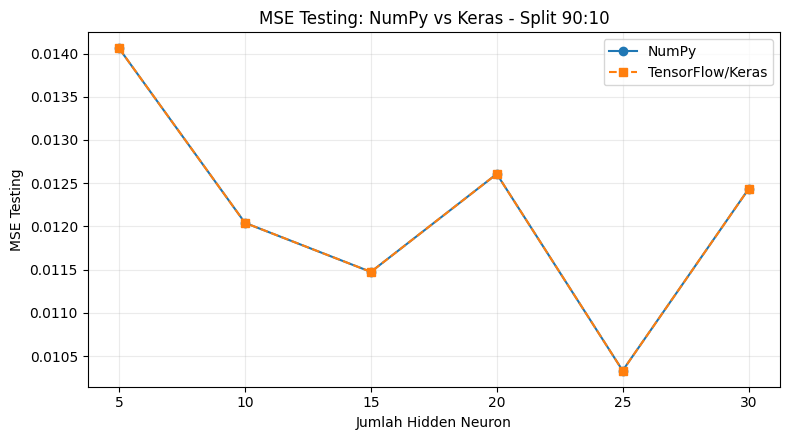

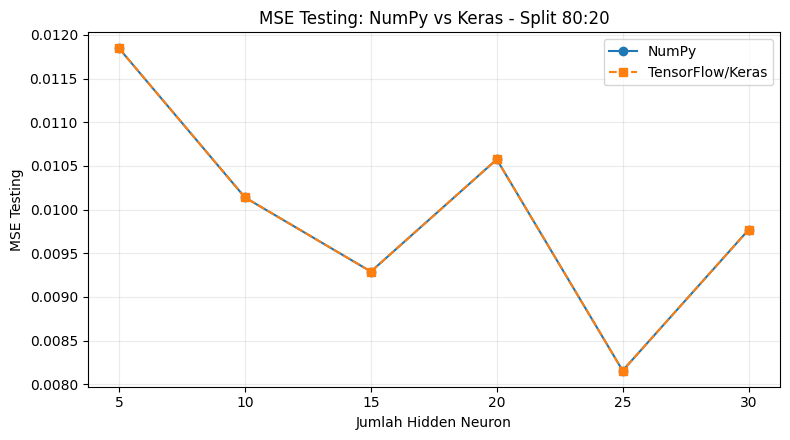

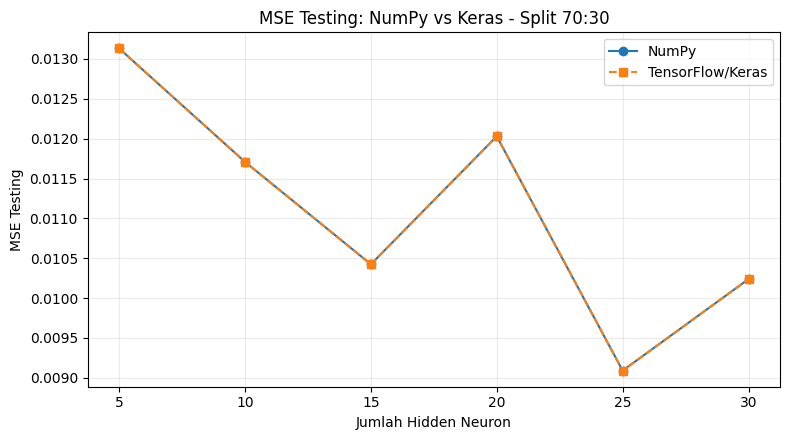

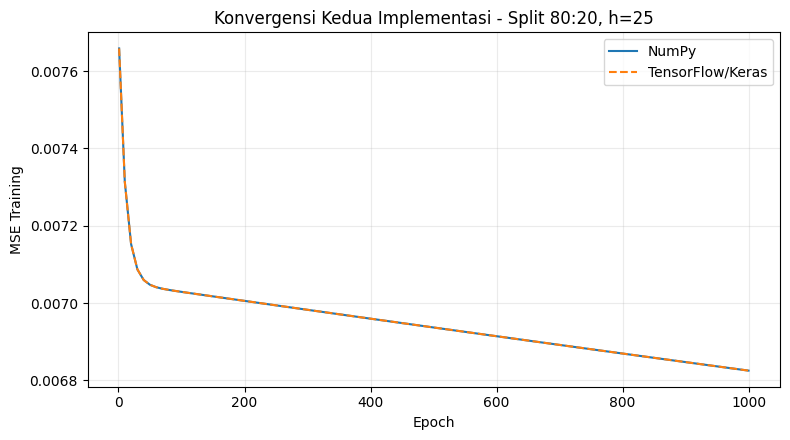

In [13]:
for scenario in split_dfs:
    plt.figure(figsize=(8, 4.5))

    np_part = comparison[comparison["split"] == scenario].sort_values("hidden")
    plt.plot(
        np_part["hidden"], np_part["mse_test_norm_numpy"],
        marker="o", label="NumPy"
    )
    plt.plot(
        np_part["hidden"], np_part["mse_test_norm_keras"],
        marker="s", linestyle="--", label="TensorFlow/Keras"
    )

    plt.title(f"MSE Testing: NumPy vs Keras - Split {scenario}")
    plt.xlabel("Jumlah Hidden Neuron")
    plt.ylabel("MSE Testing")
    plt.xticks(HIDDEN_LIST)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

scenario_check = "80:20"
hidden_check = best_numpy[scenario_check]

plt.figure(figsize=(8, 4.5))
plt.plot(
    numpy_histories[(scenario_check, hidden_check)]["epoch"],
    numpy_histories[(scenario_check, hidden_check)]["mse_training"],
    label="NumPy"
)
keras_hist = keras_histories[(scenario_check, hidden_check)]
plt.plot(
    keras_hist["epoch"],
    keras_hist["mse_training"],
    linestyle="--",
    label="TensorFlow/Keras"
)
plt.title(f"Konvergensi Kedua Implementasi - Split {scenario_check}, h={hidden_check}")
plt.xlabel("Epoch")
plt.ylabel("MSE Training")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 12. Forecast 2024–2025

File forecast menyediakan dua susunan input:
- **A:** input 2019–2022.
- **B:** input 2020–2023.

Keduanya ditampilkan sebagai dua interpretasi input. Model yang dipakai adalah model NumPy dengan MSE testing terendah pada setiap skenario split. Evaluasi forecast hanya memakai `a2024_is_filled = 0`; versi ketat juga mengeluarkan `a2024_is_thin = 1`.

,split,hidden,input,rmse_rp,rmse_strict_rp,n_valid,n_strict
0,90:10,25,A_2019_2022,768.46,766.49,261,254
1,90:10,25,B_2020_2023,803.54,800.60,261,254
2,80:20,25,A_2019_2022,793.29,791.23,261,254
3,80:20,25,B_2020_2023,828.67,825.64,261,254
4,70:30,25,A_2019_2022,828.02,825.81,261,254
5,70:30,25,B_2020_2023,864.54,861.40,261,254


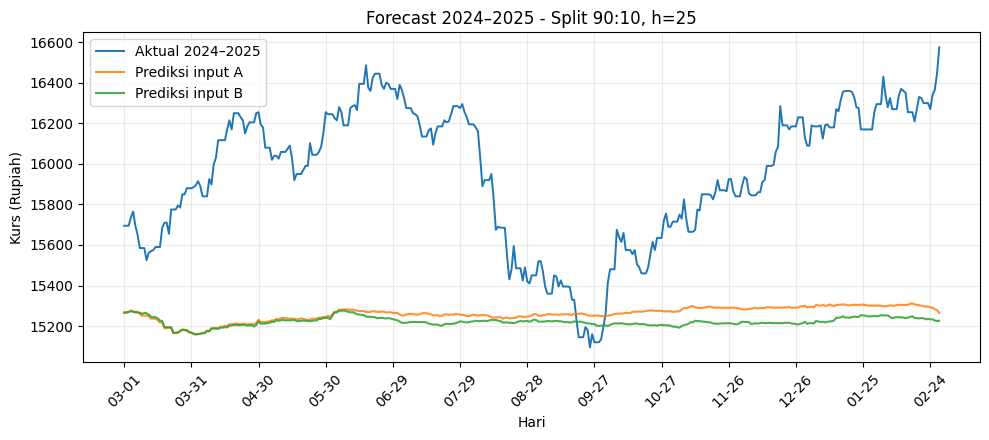

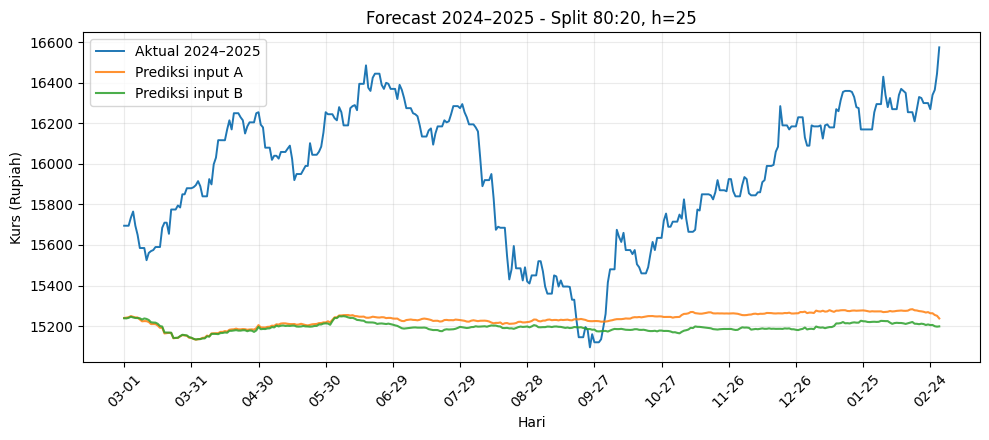

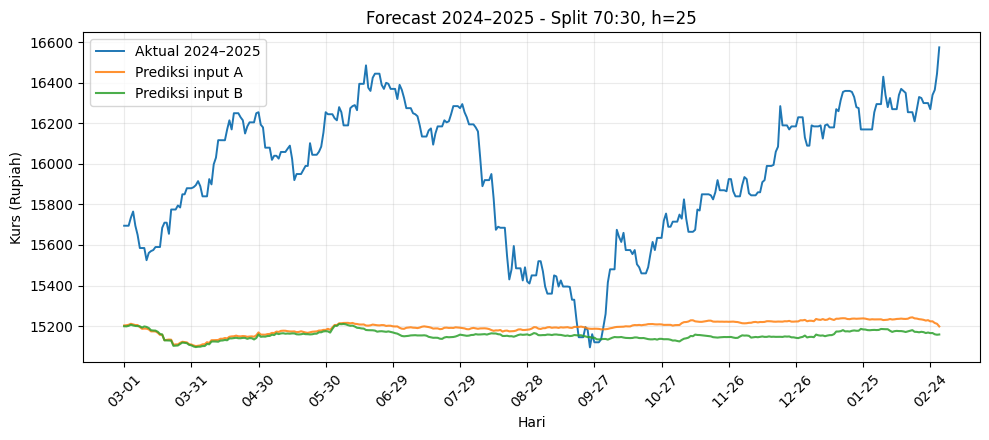

In [14]:
if forecast_df is None:
    print("File forecast tidak ditemukan. Bagian ini dilewati.")
else:
    forecast_rows = []
    forecast_predictions = {}

    forecast_masks = forecast_df["a2024_is_filled"].to_numpy() == 0
    forecast_strict = forecast_masks & (
        forecast_df["a2024_is_thin"].to_numpy() == 0
    )
    actual_forecast = forecast_df["a2024_rp"].to_numpy(dtype=float)

    for scenario, hidden in best_numpy.items():
        params = numpy_models[(scenario, hidden)]

        for label, cols in {
            "A_2019_2022": ["A_x1", "A_x2", "A_x3", "A_x4"],
            "B_2020_2023": ["B_x1", "B_x2", "B_x3", "B_x4"],
        }.items():
            X_forecast = forecast_df[cols].to_numpy(dtype=np.float64)
            pred_norm = forward_propagation(X_forecast, params)[-1].reshape(-1)
            pred_rp = denormalize(pred_norm)

            forecast_predictions[(scenario, label)] = pred_rp

            forecast_rows.append({
                "split": scenario,
                "hidden": hidden,
                "input": label,
                "rmse_rp": float(np.sqrt(np.mean(
                    (actual_forecast[forecast_masks] - pred_rp[forecast_masks]) ** 2
                ))),
                "rmse_strict_rp": float(np.sqrt(np.mean(
                    (actual_forecast[forecast_strict] - pred_rp[forecast_strict]) ** 2
                ))),
                "n_valid": int(forecast_masks.sum()),
                "n_strict": int(forecast_strict.sum()),
            })

    forecast_results = pd.DataFrame(forecast_rows)
    display(forecast_results.round(2))

    for scenario, hidden in best_numpy.items():
        plt.figure(figsize=(10, 4.5))
        plt.plot(
            forecast_df["day"], actual_forecast,
            label="Aktual 2024–2025", linewidth=1.4
        )
        plt.plot(
            forecast_df["day"],
            forecast_predictions[(scenario, "A_2019_2022")],
            label="Prediksi input A", alpha=0.85
        )
        plt.plot(
            forecast_df["day"],
            forecast_predictions[(scenario, "B_2020_2023")],
            label="Prediksi input B", alpha=0.85
        )
        plt.title(f"Forecast 2024–2025 - Split {scenario}, h={hidden}")
        plt.xlabel("Hari")
        plt.ylabel("Kurs (Rupiah)")
        plt.xticks(
            np.arange(0, len(forecast_df), 30),
            forecast_df["day"].iloc[::30],
            rotation=45
        )
        plt.legend()
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

Berdasarkan grafik peramalan selama 365 hari, terlihat bahwa hasil prediksi menggunakan input A dan input B menunjukkan pola yang relatif stabil. Kedua garis prediksi berada pada kisaran nilai yang berdekatan, yaitu sekitar Rp15.200–Rp15.300.

Jika dibandingkan dengan data aktual tahun 2024–2025, terlihat bahwa data aktual memiliki fluktuasi yang jauh lebih besar. Sementara itu, hasil prediksi model belum mampu mengikuti perubahan naik dan turunnya nilai kurs secara optimal.

Prediksi input A dan input B juga menunjukkan pola yang hampir serupa, meskipun terdapat sedikit perbedaan pada beberapa titik. Hal ini menunjukkan bahwa perubahan skenario input belum menghasilkan perbedaan prediksi yang signifikan.

## 13. Ringkasan dan ekspor hasil

File hasil disimpan agar tabel evaluasi dapat digunakan kembali untuk laporan.

In [15]:
numpy_results.to_csv("hasil_numpy_18_model.csv", index=False)
keras_results.to_csv("hasil_keras_18_model.csv", index=False)
comparison.to_csv("perbandingan_numpy_keras.csv", index=False)
underfit_df.to_csv("diagnostik_underfitting.csv", index=False)

if forecast_df is not None:
    forecast_results.to_csv("hasil_forecast_2024_2025.csv", index=False)

print("File hasil berhasil disimpan:")
print("- hasil_numpy_18_model.csv")
print("- hasil_keras_18_model.csv")
print("- perbandingan_numpy_keras.csv")
print("- diagnostik_underfitting.csv")
if forecast_df is not None:
    print("- hasil_forecast_2024_2025.csv")

File hasil berhasil disimpan:
- hasil_numpy_18_model.csv
- hasil_keras_18_model.csv
- perbandingan_numpy_keras.csv
- diagnostik_underfitting.csv
- hasil_forecast_2024_2025.csv


## 14. Catatan metode

- Arsitektur: MLP satu hidden layer, 4–h–1.
- Aktivasi: sigmoid pada hidden dan output layer.
- Optimisasi: full-batch Gradient Descent.
- Learning rate: 0,1.
- Epoch: 1.000.
- Hidden neuron: 5, 10, 15, 20, 25, dan 30.
- Split: kronologis 90:10, 80:20, dan 70:30.
- Bobot awal: Xavier/Glorot; bias awal nol; seed 42 + jumlah hidden neuron.
- Nilai learning rate 0,1 dan rumus manual dibangun sendiri. Bobot awal eksperimen penuh, seed, dan inisialisasi merupakan keputusan teknis karena tidak ditentukan untuk seluruh eksperimen pada dokumen tersebut.
- Paper menggunakan optimisasi Fletcher–Reeves, sedangkan eksperimen ini menggunakan Gradient Descent. Karena itu, notebook ini bukan replikasi persis optimisasi paper.
- Evaluasi utama mengecualikan target hasil pengisian (`t_is_filled = 1`). Evaluasi ketat juga mengecualikan data tipis/libur (`t_is_thin = 1`).